In [31]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.iolib.summary2 import summary_col
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [32]:
# Step 1: Load and filter Fama-French factor data
factors_df_path = 'D:/MG/！CUHKSZ/~！大二 下/FIN3080/Assignments/A4/STK_MKT_THRFACMONTH.xlsx'

factors_df = pd.read_excel(factors_df_path, header=0, skiprows=[0, 2], dtype={'Market Type Code': str})
factors_df = factors_df[factors_df['Market Type Code'] == 'P9706']  # SSE-SZSE A share market
factors_df['Trading Month'] = pd.to_datetime(factors_df['Trading Month'], format='%Y-%m')
factors_df.set_index('Trading Month', inplace=True)
factors = factors_df[['Market Risk Premium Factor (Weighted Average Value of Negotiable Shares)', 
                      'Book-to-Market Ratio Factor (Weighted Average Value of Negotiable Shares)']]
factors.columns = ['Market Risk', 'BM Ratio']
factors = factors.loc['2001-01':'2024-12']

In [40]:
# Step 2: Load and filter stock trading data
stock_df_path = 'D:/MG/！CUHKSZ/~！大二 下/FIN3080/Assignments/A4/TRD_Mnth.xlsx'

stock_df = pd.read_excel(stock_df_path, header=0, skiprows=[0, 2], dtype={'Stock Code': str})
stock_df = stock_df[stock_df['Market Type'].isin([1, 4])]  # SSE (1) and SZSE (4) mainboard
stock_df['Stock Code'] = stock_df['Stock Code'].astype(str).str.zfill(6)  # Ensure 6-digit codes
stock_df = stock_df[~((stock_df['Market Type'] == 1) & stock_df['Stock Code'].str.startswith('688'))]  # Exclude STAR Market
stock_df = stock_df[~((stock_df['Market Type'] == 4) & stock_df['Stock Code'].str.startswith('300'))]  # Exclude ChiNext
stock_df['Trading Month'] = pd.to_datetime(stock_df['Trading Month'], format='%Y-%m')

In [41]:
# Step 3: Create lagged market capitalization
stock_df = stock_df.sort_values(by=['Stock Code', 'Trading Month'])
stock_df['Market Cap Lag1'] = stock_df.groupby('Stock Code')['Market Value of Tradable Shares'].shift(1)

In [42]:
# Step 4: Assign deciles based on lagged market capitalization
def assign_decile(group):
    try:
        group['Decile'] = pd.qcut(group['Market Cap Lag1'], 10, labels=False, duplicates='drop')
    except ValueError:
        group['Decile'] = np.nan
    return group

stock_df = stock_df.groupby('Trading Month').apply(assign_decile).reset_index(drop=True)

C:\Users\19927\AppData\Local\Temp\ipykernel_23372\1660923022.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  stock_df = stock_df.groupby('Trading Month').apply(assign_decile).reset_index(drop=True)


In [43]:
# Step 5: Calculate equal-weighted portfolio returns
portfolio_returns = stock_df.groupby(['Trading Month', 'Decile'])['Monthly Return Without Cash Dividend Reinvested'].mean().unstack()
portfolio_returns = portfolio_returns.loc['2001-01':'2024-12']

In [44]:
# Step 6: Perform regression for each portfolio and store results
models = {}
for decile in range(10):
    y = portfolio_returns[decile].dropna()
    X = factors.loc[y.index].dropna()
    y = y.loc[X.index]  # Align dates
    X = sm.add_constant(X)
    model = sm.OLS(y, X).fit()
    models[decile] = model

# Create a summary table for all models
summary_table = summary_col(
    [models[i] for i in range(10)],
    stars=True,
    float_format='%.4f',
    model_names=[f'Portfolio {i}' for i in range(10)],
    info_dict={'N': lambda x: f"{x.nobs:.0f}", 'R2': lambda x: f"{x.rsquared:.4f}"}
)

print("\nRegression Summaries for All Portfolios:")
print(summary_table)


Regression Summaries for All Portfolios:

               Portfolio 0 Portfolio 1 Portfolio 2 Portfolio 3 Portfolio 4 Portfolio 5 Portfolio 6 Portfolio 7 Portfolio 8 Portfolio 9
--------------------------------------------------------------------------------------------------------------------------------------
const          0.0250***   0.0146***   0.0113***   0.0084***   0.0062**    0.0051**    0.0044*     0.0033      0.0030*     0.0019*    
               (0.0042)    (0.0033)    (0.0030)    (0.0028)    (0.0028)    (0.0025)    (0.0023)    (0.0020)    (0.0017)    (0.0010)   
Market Risk    1.0212***   1.0273***   1.0330***   1.0567***   1.0383***   1.0418***   1.0605***   1.0540***   1.0483***   1.0507***  
               (0.0581)    (0.0453)    (0.0419)    (0.0392)    (0.0382)    (0.0348)    (0.0318)    (0.0280)    (0.0241)    (0.0144)   
BM Ratio       -1.0998***  -0.9232***  -0.8389***  -0.7535***  -0.7268***  -0.7183***  -0.6085***  -0.5515***  -0.4187***  -0.0346    
            

In [45]:
# Step 7: Summarize regression coefficients
results = {}
for decile in range(10):
    model = models[decile]
    results[decile] = {
        'Intercept': model.params['const'],
        'Market Risk Beta': model.params['Market Risk'],
        'BM Ratio Beta': model.params['BM Ratio'],
        'Intercept p-value': model.pvalues['const'],
        'Market Risk p-value': model.pvalues['Market Risk'],
        'BM Ratio p-value': model.pvalues['BM Ratio'],
        'R-squared': model.rsquared
    }

results_df = pd.DataFrame(results).T
results_df = results_df.round(4)
results_df.index.name = 'Portfolio Decile'

# Highlight significant p-values (p < 0.05)
def highlight_significant(s):
    is_significant = s < 0.05
    return ['background-color: yellow' if v else '' for v in is_significant]

styled_results_df = results_df.style.apply(highlight_significant, subset=['Intercept p-value', 'Market Risk p-value', 'BM Ratio p-value'])
print("\nSummary of Regression Coefficients:")
display(styled_results_df)


Summary of Regression Coefficients:


,Intercept,Market Risk Beta,BM Ratio Beta,Intercept p-value,Market Risk p-value,BM Ratio p-value,R-squared
Portfolio Decile,,,,,,,
0,0.025000,1.021200,-1.099800,0.000000,0.000000,0.000000,0.599000
1,0.014600,1.027300,-0.923200,0.000000,0.000000,0.000000,0.698900
2,0.011300,1.033000,-0.838900,0.000200,0.000000,0.000000,0.726700
3,0.008400,1.056700,-0.753500,0.003200,0.000000,0.000000,0.754100
4,0.006200,1.038300,-0.726800,0.026500,0.000000,0.000000,0.756400
5,0.005100,1.041800,-0.718300,0.043600,0.000000,0.000000,0.789400
6,0.004400,1.060500,-0.608500,0.054400,0.000000,0.000000,0.818100
7,0.003300,1.054000,-0.551500,0.100100,0.000000,0.000000,0.849100
8,0.003000,1.048300,-0.418700,0.082700,0.000000,0.000000,0.879200


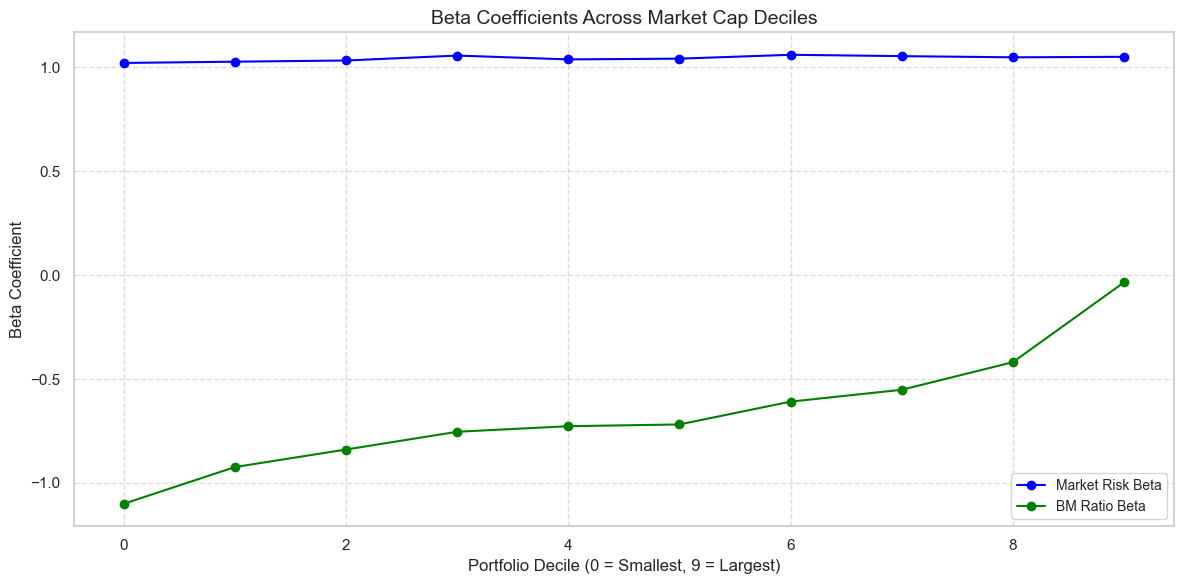

In [46]:
# Step 8: Plot betas across deciles
plt.figure(figsize=(12, 6))
plt.plot(results_df.index, results_df['Market Risk Beta'], label='Market Risk Beta', marker='o', color='blue')
plt.plot(results_df.index, results_df['BM Ratio Beta'], label='BM Ratio Beta', marker='o', color='green')
plt.xlabel('Portfolio Decile (0 = Smallest, 9 = Largest)', fontsize=12)
plt.ylabel('Beta Coefficient', fontsize=12)
plt.title('Beta Coefficients Across Market Cap Deciles', fontsize=14)
plt.legend(loc='best', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

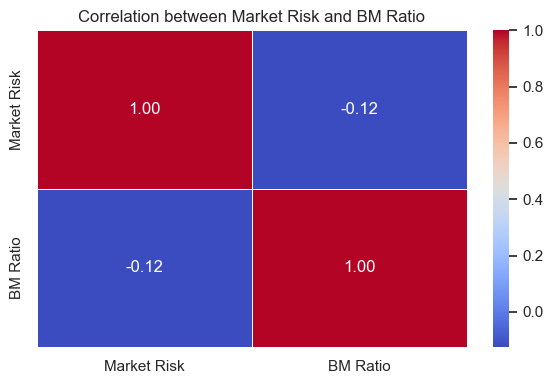

In [48]:
# Step 9: Check correlation between factors
corr_matrix = factors[['Market Risk', 'BM Ratio']].corr()
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation between Market Risk and BM Ratio', fontsize=12)
plt.tight_layout()
plt.show()

# Regression Analysis Summary for Portfolios Sorted by Market Capitalization

## Intercept (α)

- **Trend**: Decreases from 0.0250 (Portfolio 0) to 0.0019 (Portfolio 9).
- **Significance**:
    - Highly significant (p < 0.05 or p < 0.01) for Portfolios 0–5.
    - Marginally significant (p < 0.1) for Portfolios 6, 8, 9.
    - Not significant (p > 0.1) for Portfolio 7.
- **Insight**: Small-cap portfolios show excess returns, while large-cap returns are better explained by the model.

## Market Risk Beta (β₁)

- **Trend**: Stable, ranging from 1.0212 (Portfolio 0) to 1.0605 (Portfolio 6), with 1.0507 for Portfolio 9.
- **Significance**: Highly significant (p < 0.01) across all portfolios.
- **Insight**: All portfolios are slightly more market-sensitive than the market itself, with minimal variation by size.

## Book-to-Market Ratio Beta (β₂)

- **Trend**: Negative, decreasing from -1.0998 (Portfolio 0) to -0.0346 (Portfolio 9).
- **Significance**:
    - Highly significant (p < 0.01) for Portfolios 0–8.
    - Not significant (p = 0.2778) for Portfolio 9.
- **Insight**: Negative BM betas suggest an unexpected relationship with value, especially pronounced in small-caps.

## R-squared

- **Trend**: Increases from 0.5990 (Portfolio 0) to 0.9501 (Portfolio 9).
- **Insight**: Model fit improves with market cap, indicating better explanatory power for large-cap stocks.

## Conclusion

Small-cap portfolios exhibit excess returns and a weaker model fit, while large-cap portfolios align closely with the Fama-French factors. The negative BM beta is a notable anomaly requiring further exploration.